In [1]:
from hofmann import StructureScene
from hofmann import CellEdgeStyle, RenderStyle
from pymatgen.io.ase import AseAtomsAdaptor as aaa
import matplotlib.pyplot as plt
from chgnet.model.dynamics import CHGNetCalculator
from smilesbox.smilesbox import SMILESbox

from claude_code.neb_runner import NEBRunner
from claude_code.complex_builder import ComplexBuilder, ElementPair

Overall reaction: 2 NO + O2 = 2 NO2 

assuming intermediate steps: 

1. NO + O2 = NO3 
2. NO3 + NO = 2 NO2 

In [2]:
species = {
    "NO":"[N]=O",
    "O2":"O=O",
    "NO3":"[N+](=O)([O-])[O-]",
    "NO2":"N(=O)[O]",
    #"N2O2":"N(=O)N=O"
    }

species_atoms = {spec:SMILESbox(smiles).atoms for spec,smiles in species.items()}
species_atoms

{'NO': Atoms(symbols='NO', pbc=False),
 'O2': Atoms(symbols='O2', pbc=False),
 'NO3': Atoms(symbols='NO3', pbc=False),
 'NO2': Atoms(symbols='NO2', pbc=False)}

In [3]:
builder = ComplexBuilder(cell_size=12.0, approach_scale=1.8)
route = [
    {'reactants': ['NO', 'O2'], 'products': ['NO3']},
    {'reactants': ['NO3', 'NO'], 'products': ['NO2', 'NO2']},
    #{'reactants': ['NO', 'NO'], 'products': ['N2O2']},
    #{'reactants': ['N2O2', 'O2'], 'products': ['NO2', 'NO2']},    
]

# Build all complexes in one call
steps = builder.build_all_steps(
    route,
    species_atoms,
    forming_bonds={
        '2NO+O2->NO3': ElementPair('N', 'O'),
       # "2NO->N2O2":ElementPair("N","O"),
       # "N2O2+O2->2NO2":ElementPair("N","O")
        'NO3+NO->2NO2': ElementPair('N', 'O'),
    }
)

[ComplexBuilder] 
Building: NO+O2->NO3
[ComplexBuilder] Reactant: NO3  (4 atoms)
[ComplexBuilder] Product:  NO3  (4 atoms)
[ComplexBuilder] Solving atom mapping...
[ComplexBuilder] Bonds formed: [('N', 'O'), ('N', 'O')]
[ComplexBuilder] Bonds broken: [('O', 'O')]
[ComplexBuilder]   Reactive pair: N(frag_a[0]) -- O(frag_b[0])  target separation = 2.47 Å
[ComplexBuilder] Done.
[ComplexBuilder] 
Building: NO3+NO->NO2+NO2
[ComplexBuilder] Reactant: N2O4  (6 atoms)
[ComplexBuilder] Product:  N2O4  (6 atoms)
[ComplexBuilder] Solving atom mapping...
[ComplexBuilder] Bonds formed: [('O', 'N')]
[ComplexBuilder] Bonds broken: [('N', 'O')]
[ComplexBuilder]   Reactive pair: O(frag_a[3]) -- N(frag_b[0])  target separation = 2.47 Å
[ComplexBuilder] Done.


In [4]:
steps[0]

{'label': 'NO+O2->NO3',
 'reactant': Atoms(symbols='NO3', pbc=True, cell=[12.0, 12.0, 12.0]),
 'product': Atoms(symbols='NO3', pbc=True, cell=[12.0, 12.0, 12.0])}

In [5]:
from ase.visualize import view
step = 0
view([steps[step]["reactant"], steps[step]["product"]],viewer="ngl")

In [6]:
runner = NEBRunner(
    calc_factory=lambda: CHGNetCalculator(
        use_device="mps", on_isolated_atoms="ignore"),
    n_images=3,
    fmax_relax=0.1,
    fmax_neb=0.1,
    climb=False
)

In [7]:
results = runner.run_batch(steps, output_base="claude_neb_test_job")

[NEBRunner] 
Step 1/2: NO+O2->NO3
[NEBRunner] =======================================================
[NEBRunner] NEB: NO+O2->NO3
[NEBRunner] =======================================================
[NEBRunner] Relaxing reactant...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps


/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/chgnet/model/model.py:898: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:839.)
  volumes = torch.tensor(volumes, dtype=TORCH_DTYPE, device=atomic_numbers.device)


[NEBRunner]   NO+O2->NO3_R: E = -22.907463 eV  (OK)
[NEBRunner] Relaxing product...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
[NEBRunner]   NO+O2->NO3_P: E = -25.268812 eV  (OK)
[NEBRunner]   E_R = -22.907463  E_P = -25.268812  dE = -2.361349 eV
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
[NEBRunner] Interpolating (idpp, 5 images)...
[NEBRunner] Pre-relaxing path...
[NEBRunner] CI-NEB converged
[NEBRunner] 
NEB result [converged]: NO+O2->NO3
  delta_E     = -2.3613 eV
  Ea(forward) = 0.2010 eV
  Ea(reverse) = 2.5623 eV
  TS image    = 2 / 4

[NEBRunner] 
Step 2/2: NO3+NO->NO2+NO2
[NEBRunner] =======================================================
[NEBRunner] NEB: NO3+NO->NO2+NO2
[NEBRunner] =======================================================
[NEBRunner] Relaxing reactant...
CHGNe

/Users/badw/github-projects/arcs-kinetics/notebooks/claude_code/neb_runner.py:327: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


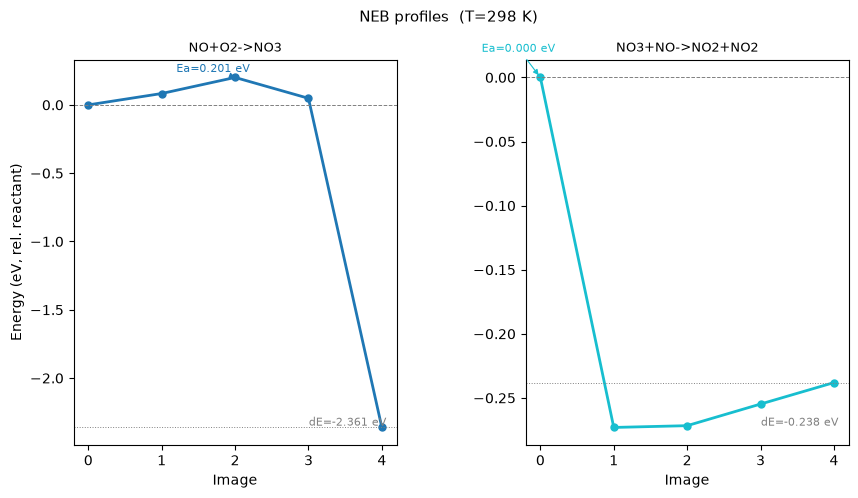

In [8]:
from claude_code.neb_runner import plot_energy_profiles
plot_energy_profiles(results)
plt.show()

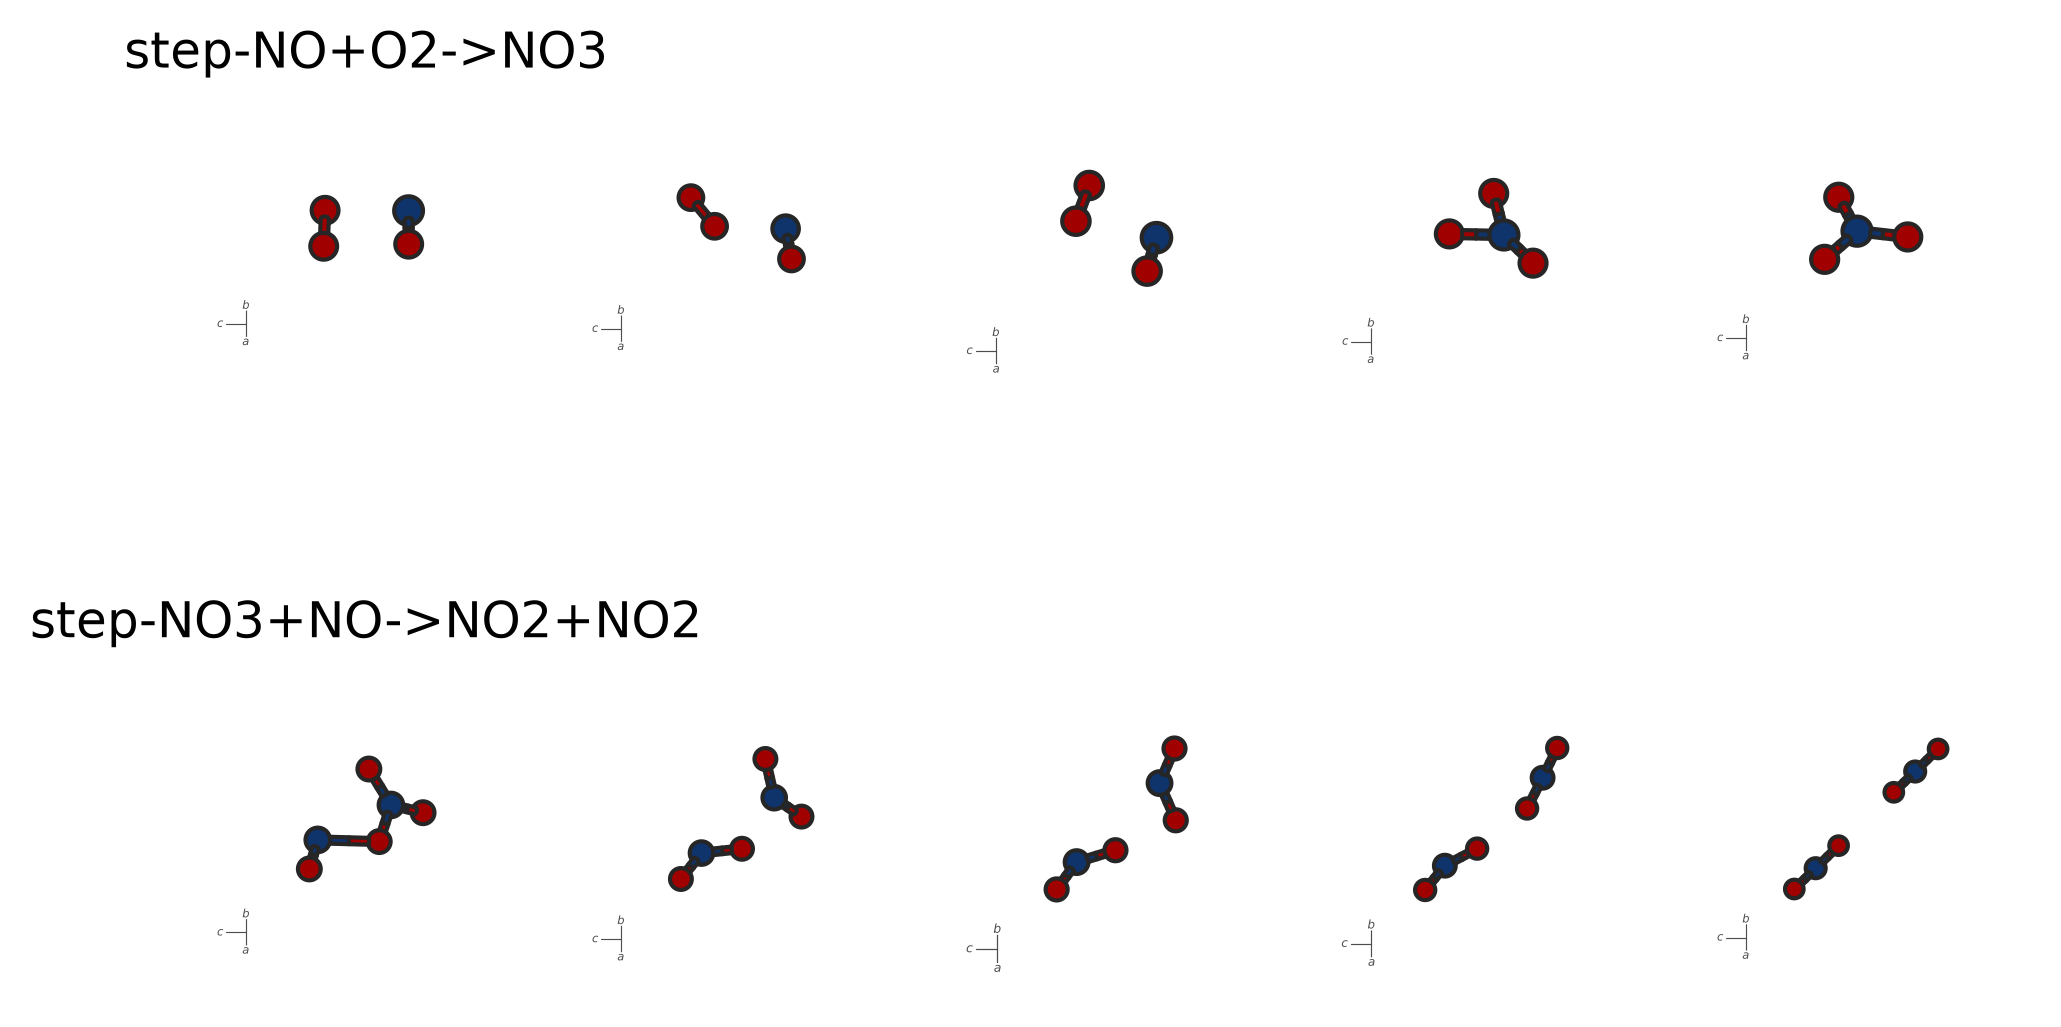

In [9]:
fig,axes = plt.subplots(nrows=len(results),ncols=len(results[0].images),dpi=300)
style = RenderStyle(
    cell_style=CellEdgeStyle(
        line_width=0
    ),
)
ax_flat = axes.flatten()
i = 0 
for result in results:
    ax_flat[i].set_title(f"step-{result.label}")
    for image in result.images:
        scene = StructureScene.from_pymatgen(aaa.get_structure(image))
        scene.view.zoom = 0.5  # Zoom in
        scene.view.look_along([1,1,0])
        scene.render_mpl(ax=ax_flat[i],style=style)
        i+=1
    


plt.tight_layout()

In [10]:
view(results[1].images,viewer="ngl")


Microkinetic Model
  T = 298.0 K  |  P = 40.000 atm
  Concentration unit: ppm @ 298K/40.00atm  (1 unit = 1.6358e-06 mol/L)
  2 elementary steps  |  4 species
  Species: ['NO', 'O2', 'NO3', 'NO2']

  Prefactor kT/h = 6.209e+12 s⁻¹  (T = 298 K)
  NO + O2 -> NO3
    Ea_fwd = 0.2010 eV  kf = 4.0572e+03  kr = 2.8714e-31  Keq = 1.4130e+34
  NO3 + NO -> 2NO2
    Ea_fwd = 0.0000 eV  kf = 1.0157e+07  kr = 9.5752e+02  Keq = 1.0608e+04

  Solving steady state (algebraic)...
  Steady state converged.
  Computing degree of rate control (DRC)...
  Building time-evolution profile (LSODA, t=1.00e+00 s)...

MICROKINETIC MODEL REPORT
  T = 298.0 K  |  P = 40.000 atm
  Integration: converged

─────────────────────────────────────────────────────────────────
  Rate constants (Eyring, T = 298.0 K)
  Step                           kf (s⁻¹ or L/mol/s)                    kr
  ────────────────────────────────────────────────────────────────
  NO + O2 -> NO3                          4.0572e+03            2.871

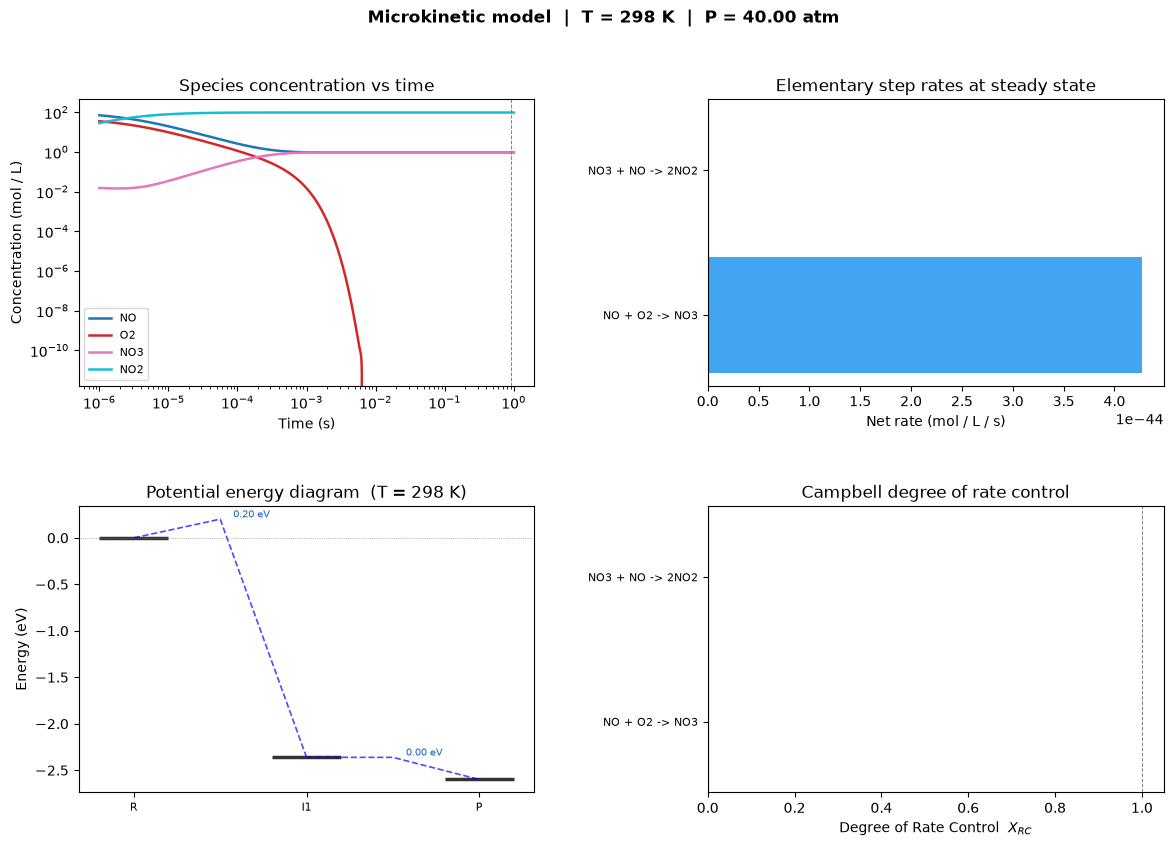

In [29]:
from claude_code.microkinetic_model import MicroKineticModel, ElementaryStep, ConcentrationUnit


# neb_results comes directly from runner.run_batch(...)
steps = [
    ElementaryStep(
        label     = "NO + O2 -> NO3",
        reactants = {"NO": 1, "O2": 1},
        products  = {"NO3": 1},
        neb_result= results[0],
    ),
    ElementaryStep(
        label     = "NO3 + NO -> 2NO2",
        reactants = {"NO3": 1, "NO": 1},
        products  = {"NO2": 2},
        neb_result= results[1],
    ),
]

#steps = [
#    ElementaryStep(
#        label     = "NO + NO -> N2O2",
#        reactants = {"NO": 2},
#        products  = {"N2O2": 1},
#        neb_result= results[0],
#    ),
#    ElementaryStep(
#        label     = "N2O2 + O2 -> 2 NO2",
#        reactants = {"N2O2": 1, "O2": 1},
#        products  = {"NO2": 2},
#        neb_result= results[1],
#    ),
#]

model = MicroKineticModel(
    steps        = steps,
    temperature  = 298,
    pressure     = 40,
    conc_unit    = ConcentrationUnit.ppm(T=298, P_atm=40),
    initial_conc = {"NO": 100.0, "O2": 50.0},   # 100 ppm NO, 50 ppm O2
    target_reaction = "2NO + O2 -> 2NO2",
    t_end=1
)

result = model.run()   # prints full report automatically
result.plot()
plt.show()

In [ ]:
#rtp and 40 bar 

#2NO + O2 = 2NO2 = 1.8626e-9 (or 1e34)

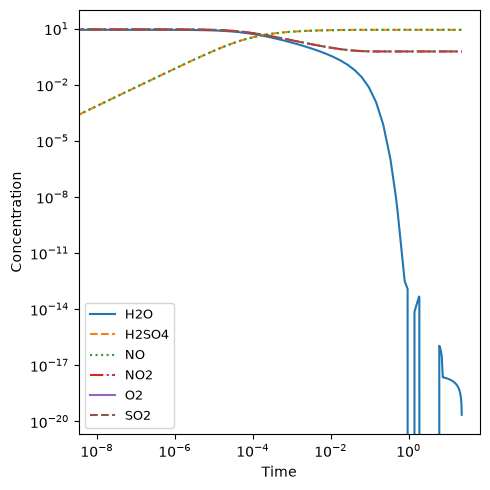

In [30]:
from chempy import ReactionSystem,Reaction  # The rate constants below are arbitrary
rsys = ReactionSystem(
    [
        Reaction.from_string("2 NO + O2 -> 2 NO2 ; 1e34"),
        Reaction.from_string("SO2 + H2O + NO2 -> H2SO4 + NO ; 1e2")
        ]
        )
from chempy.kinetics.ode import get_odesys
odesys, extra = get_odesys(rsys)
from collections import defaultdict
import numpy as np
tout = sorted(np.concatenate((np.linspace(0, 23), np.logspace(-8, 1))))
c0 = defaultdict(float, {'NO2': 9.2, "SO2":9.2,"H2O":8.6})
result = odesys.integrate(tout, c0, atol=1e-12, rtol=1e-14)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
for ax in [axes]:
    _ = result.plot(names=[k for k in rsys.substances], ax=ax)
    _ = ax.legend(loc='best', prop={'size': 9})
    _ = ax.set_xlabel('Time')
    _ = ax.set_ylabel('Concentration')
#_ = axes.set_ylim([1e-13, 1e-1])
_ = axes.set_xscale('log')
_ = axes.set_yscale('log')
_ = fig.tight_layout()